We can only put float64/int64, because they occupy contiguos memory space we have to konow what type of object is 

In [1]:
import numpy as np

a = np.array([1., 2., 3.])
m = np.array([[1, 0], [0, 1]])

for item in a, m:
    print(item)
    print(f"Data type: {item.dtype}, shape: {item.shape}")


[1. 2. 3.]
Data type: float64, shape: (3,)
[[1 0]
 [0 1]]
Data type: int64, shape: (2, 2)


In [ ]:
import numpy as numpy
#ways to initialize an array
print(f"zeros -> {np.zeros(5)}")
print(f"ones -> {np.ones(5)}")
print(f"full -> {np.full(5, 3.3)}")
print(f"linspace -> {np.linspace(0., 1., 5)}")
print(f"geomspace -> {np.geomspace(0.1, 1., 5)}")
print(f"logspace -> {np.logspace(-1, 0, 5)}")
print(f"arange -> {np.arange(0., 1.001, 0.2)}")

zeros -> [0. 0. 0. 0. 0.]
ones -> [1. 1. 1. 1. 1.]
full -> [3.3 3.3 3.3 3.3 3.3]
linspace -> [0.   0.25 0.5  0.75 1.  ]
geomspace -> [0.1        0.17782794 0.31622777 0.56234133 1.        ]
logspace -> [0.1        0.17782794 0.31622777 0.56234133 1.        ]
arange -> [0.  0.2 0.4 0.6 0.8 1. ]


we can sum a list with another list to concatenate them and multiply by a scalar means repeating the list n-times. on array you sum and multiply element by element.

In [3]:
import numpy as np

l = [1, 2, 3]
a = np.array([1, 2, 3])

print(l)
print(a)

l = [1, 2, 3]
a = np.array([1, 2, 3])

print(f"sum: {l + l} vs. {a + a}")
print(f"multiplication by a scalar: {l * 2} vs. {a * 2}")

[1, 2, 3]
[1 2 3]
sum: [1, 2, 3, 1, 2, 3] vs. [2 4 6]
multiplication by a scalar: [1, 2, 3, 1, 2, 3] vs. [2 4 6]


the last element is 0 because the number is too large to be represented in numpy. in python this doesn't happen. be careful

In [4]:
import numpy as np

a = np.array([2, 4, 8, 16])

print(a.dtype)
print(a**16)

int64
[          65536      4294967296 281474976710656               0]


In [ ]:
import numpy as np

a = np.linspace(0, 15, 16, dtype=int).reshape((4, 4))#to create a matrix

print(a)
print(a[0])
print(a[0][3], a[3][0])
print(a[0, 3], a[3, 0])

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]]
[0 1 2 3]
3 12
3 12


mask is an array of boolean values used to filter other array

In [6]:
import numpy as np

a = np.linspace(0, 15, 16, dtype=int)

print(a)
print(a[2:6])
print(a[0:16:2])

a = a.reshape((4, 4))

print(a)
print(a[1:3, 1:3])

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]
[2 3 4 5]
[ 0  2  4  6  8 10 12 14]
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]]
[[ 5  6]
 [ 9 10]]


In [9]:
import numpy as np

a = np.linspace(0, 15, 16, dtype=int)
b = np.array([1, 3, 5, 7, 11])
c = np.array([True, False] * 8)
d=a<=5

print(a)
print(a[b])
print(a[c])
print(a[d])

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]
[ 1  3  5  7 11]
[ 0  2  4  6  8 10 12 14]
[0 1 2 3 4 5]


if the array has the same size is obvious the multiplication and the sum. if they are different?
for some type of good matching of dimension it is permitted

In [18]:
import numpy as np

c = np.pi
a1 = np.array([1, 2, 3, 4])
a2 = np.linspace(0, 15, 16, dtype=int).reshape((4, 4))

print(c)
print(a1)
print(a2)

print(a1 * c)#multiply a vector by a scalar
print(a2 * c)#multiply a matrix by a scalar
print(a1 * a2)#multiply a matrix by a vector
print(a2 * a1)#the order doesn't count

3.141592653589793
[1 2 3 4]
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]]
[ 3.14159265  6.28318531  9.42477796 12.56637061]
[[ 0.          3.14159265  6.28318531  9.42477796]
 [12.56637061 15.70796327 18.84955592 21.99114858]
 [25.13274123 28.27433388 31.41592654 34.55751919]
 [37.69911184 40.8407045  43.98229715 47.1238898 ]]
[[ 0  2  6 12]
 [ 4 10 18 28]
 [ 8 18 30 44]
 [12 26 42 60]]
[[ 0  2  6 12]
 [ 4 10 18 28]
 [ 8 18 30 44]
 [12 26 42 60]]


not everything has to be optimize, if it's takin 100 micros, it's ok. it is faster to use numpy because we're using C-language hidden in the functions code

In [24]:
import random
import time
import numpy as np

n = 1000000

# The slow way: explicit for loop in Python. i have to keep track of lots of things because i more free
t0 = time.time()
x = []
for i in range(n):
    x.append(random.random())
dt = time.time() - t0
print("Elapsed time: %.4f s" % dt)

# The quick way: using numpy. it's using C-language
t0 = time.time()
x = np.random.random(size=n)
dt = time.time() - t0
print("Elapsed time: %.4f s" % dt)

Elapsed time: 0.1033 s
Elapsed time: 0.0144 s


vectorization is important because you reduce the time of calculations. You have to absolutely review this code!!!

Simulation completed in 0.555 s


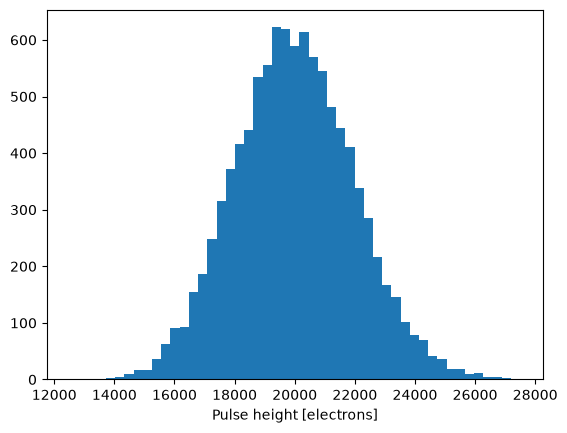

In [27]:
import random
import time

import numpy as np
from matplotlib import pyplot as plt

num_photons = 10000
E_0 = 6000. # eV
W_i = 30. # eV
G = 100.

pha = []
t0 = time.time()

# Outer loop over the impinging X-rays.
for i in range(num_photons):
    # Initialize the total number of the electron-ion pairs that are created
    # by ionization for this particular event.
    total_ionization = 0
    # Extract the number of primary electrons created by the photoelectron.
    # Too bad the random module in the standard lib does not provide the
    # Poisson distribution, and we do have to resort to numpy...
    num_primaries = np.random.poisson(E_0 / W_i)
    # Inner loop over the primary electrons...
    for j in range(num_primaries):
        # For each primary electron, extract the number of electron-ion pairs
        # generated in the avalanche.
        total_ionization += random.expovariate(1. / G)
    pha.append(total_ionization)

dt = time.time() - t0
plt.hist(pha, bins=np.linspace(12500., 27500., 50))
plt.xlabel("Pulse height [electrons]")
print(f"Simulation completed in {dt:.3f} s")

[197 197 225 ... 204 219 195]
Simulation completed in 0.038 s


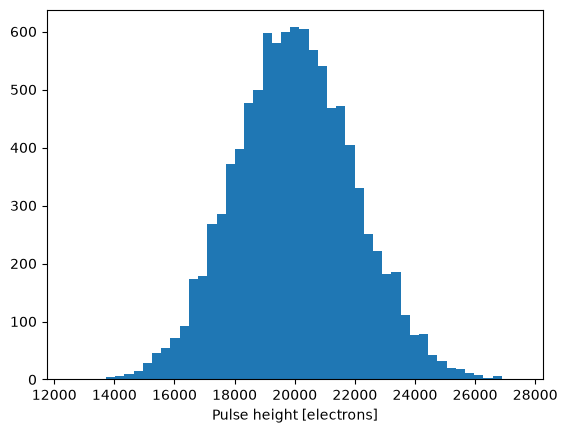

In [ ]:
import time

import numpy as np
from matplotlib import pyplot as plt

rng = np.random.default_rng()

num_photons = 10000
E_0 = 6000. # eV
W_i = 30. # eV
G = 100.


t0 = time.time()

# Create an array with the number of primaries for each single X-ray.
num_primaries = rng.poisson(E_0 / W_i, size=num_photons)
# Populate an array with as many copies of the event id as the corresponding
# primary electrons
event_id = np.repeat(np.arange(num_photons), num_primaries)
# Extract the gain for each single primary electron.
event_gain = rng.exponential(scale=G, size=event_id.size)
# Sum all the ionization pairs, on an event-by-event basis, to get the "energy".
pha = np.bincount(event_id, weights=event_gain, minlength=num_photons)

dt = time.time() - t0
plt.hist(pha, bins=np.linspace(12500., 27500., 50))
plt.xlabel("Pulse height [electrons]")
print(f"Simulation completed in {dt:.3f} s")

testing the code in a way to recognize errors. you have to move the test in another code in a folder and call pytest that reports the succesfull test and the fail. in metarep there is a precise code wich automatically test your code with pytest

In [ ]:
def square(x):
    """Toy function returning the square of x.
    """
    return x**2.

def test():
    """Dumb test battery.
    """
    assert square(2.) == 4.
    assert square(2) == 4.#assert: make an AssertError if the statement is false
    assert square(-2.) == 4.
    print("All tests passed!")


if __name__ == "__main__":
    test()

static analysis search for hidden error, such as that z in programm. the condition is false, so python doesn't read the line, but it will happen a day. pylint is a way to test yoour code

In [35]:
x = 1.
y = 2.
very_uncommon_condition = False
if very_uncommon_condition:
    print(x + z)
else:
    print(x + y)

3.0


i install pytest and every file that begin with test activate suddenly. pylint test in a way it likes a single file. i activate with python -m pylint nome_code.py

every time a merge a pull request, the "doc.yml" documentation file is run